# 02 · Filtro, latidos y serie RR

**Pregunta de este notebook.** ¿Cómo se pasa del ECG crudo a una serie RR confiable? Cada paso responde a un problema que se vio en `01`:

1. **Filtro**: sacar la deriva de línea de base y el ruido de alta frecuencia sin deformar el latido.
2. **Latidos**: ubicar cada pico R. Se comparan las marcas de la base con un detector propio (Pan-Tompkins) y se decide cuál usar en cada registro.
3. **Refinamiento**: a 100 Hz el pico R cae en una grilla de 10 ms; se mide si vale la pena corregirlo.
4. **Limpieza del RR**: corregir los intervalos imposibles (latidos perdidos, de más o ectópicos).

Nada de este notebook usa las etiquetas de apnea: todas las decisiones salen de las señales de los 47 registros de desarrollo.

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from src.config import ECG_FILTER, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.features.edr import qrs_reference
from src.preprocessing.filters import (apply_zero_phase, beat_spectrum, cumulative_energy_freq,
                                       design_bandpass, frequency_response, meets_spec)
from src.qrs.beats import record_beats
from src.qrs.pan_tompkins import (detect_r_peaks, pan_tompkins_signals, r_peaks_from_marks,
                                  refine_peaks_parabolic, validate_against_reference)
from src.qrs.quantization import two_phase_peaks
from src.qrs.rr_clean import clean_rr, minute_quality
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
FS = 100.0

## 1. El filtro

**Qué tiene que hacer** (de `01`): sacar la deriva por debajo de ~0,5 Hz y el ruido por encima de ~40 Hz, incluida la línea de 50 Hz, sin tocar el latido.

**Especificación**, sacada de los registros de desarrollo:
- **Límite inferior de la banda de paso**: la frecuencia cardíaca más baja, medida como el percentil 1 de la frecuencia instantánea (1/RR) de todos los latidos. Por debajo de ella no hay energía del latido, solo deriva.
- **Límite superior de la banda de paso**: la frecuencia por debajo de la cual está el 99 % de la energía del latido mediano de cada registro, tomando el percentil 95 entre registros (el registro más exigente es un caso aislado).
- En la banda de paso la atenuación tiene que ser de **1 dB o menos**, y a 0,1 Hz (deriva lenta) de **20 dB o más**.

**Diseño.** Butterworth pasabanda (respuesta plana en la banda de paso) aplicado **ida y vuelta** (`sosfiltfilt`): la fase total es cero, así que no corre el pico R ni deforma el QRS, y la ganancia efectiva es |H(f)|². El corte alto se elige por debajo de 50 Hz, donde está la interferencia; el bajo, en 0,5 Hz, el valor habitual para monitoreo de ECG. Se elige el **menor orden** que cumple la especificación (menos oscilación en el tiempo y menos transitorio en los bordes).

In [2]:
f99, fc = [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    qrs = load_qrs(rec)
    off, sign = qrs_reference(ecg, qrs, fs)
    peaks = np.rint(r_peaks_from_marks(ecg, qrs, fs, off, sign)[0] * fs).astype(int)
    f, p = beat_spectrum(ecg, peaks, fs)
    f99.append(cumulative_energy_freq(f, p, 0.99))
    _, rr, corr = clean_rr(peaks / fs)
    fc.append(1 / rr[~corr])
F_FC_MIN = float(np.percentile(np.concatenate(fc), 1))
F_QRS = float(np.percentile(f99, 95))
print(f"límite inferior: {F_FC_MIN:.2f} Hz ({60 * F_FC_MIN:.0f} lpm) · límite superior: {F_QRS:.1f} Hz")

filas = []
for lo in (0.3, 0.5, 0.7):
    for hi in (35, 40, 45):
        orden = next((n for n in range(1, 9)
                      if meets_spec(design_bandpass(FS, lo, hi, n), FS, (F_FC_MIN, F_QRS), {0.1: 20}, 1.0)), None)
        filas.append({"corte bajo (Hz)": lo, "corte alto (Hz)": hi, "menor orden que cumple": orden})
pd.DataFrame(filas).pivot(index="corte bajo (Hz)", columns="corte alto (Hz)", values="menor orden que cumple")

límite inferior: 0.77 Hz (46 lpm) · límite superior: 41.8 Hz


corte alto (Hz),35,40,45
corte bajo (Hz),,,
0.3,NaN,NaN,3.0
0.5,NaN,NaN,3.0
0.7,NaN,NaN,NaN


Con corte alto de 35 o 40 Hz ningún orden cumple: el filtro atenuaría parte del QRS. Con 45 Hz, el menor orden que cumple con el corte bajo de 0,5 Hz es 3: **pasabanda Butterworth 0,5–45 Hz, orden 3, ida y vuelta**.

atenuación en los límites de la banda de paso: {'0.77 Hz': 0.62, '41.79 Hz': 0.39} · a 0,1 Hz: 84.0 dB


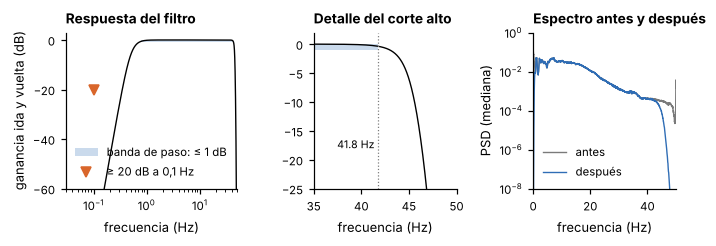

In [3]:
sos = design_bandpass(FS, *ECG_FILTER)
r = frequency_response(sos, FS, n=2 ** 16)
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
for a, xlim, xscale in ((ax[0], (0.03, 50), "log"), (ax[1], (35, 50), "linear")):
    a.plot(r["f"], r["ganancia_db_ida_vuelta"], color="black")
    a.fill_between([F_FC_MIN, F_QRS], -1, 0, color=NORMAL, alpha=0.25, lw=0, label="banda de paso: ≤ 1 dB")
    a.plot([0.1], [-20], marker="v", color=APNEA, ls="none", label="≥ 20 dB a 0,1 Hz")
    a.set(xscale=xscale, xlim=xlim, xlabel="frecuencia (Hz)")
ax[0].set(ylim=(-60, 3), ylabel="ganancia ida y vuelta (dB)", title="Respuesta del filtro")
ax[0].legend(loc="lower right")
ax[1].set(ylim=(-25, 2), title="Detalle del corte alto")
ax[1].axvline(F_QRS, color=GRIS, ls=":", lw=0.8)
ax[1].text(F_QRS - 0.4, -18, f"{F_QRS:.1f} Hz", ha="right", fontsize=7)
psd_antes, psd_despues = [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    ff, p0 = welch(ecg - ecg.mean(), fs=fs, nperseg=4096)
    _, p1 = welch(apply_zero_phase(ecg, sos), fs=fs, nperseg=4096)
    norma = np.trapezoid(p0, ff)                       # los dos con la potencia del crudo
    psd_antes.append(p0 / norma); psd_despues.append(p1 / norma)
ax[2].semilogy(ff, np.median(psd_antes, axis=0), color=GRIS, label="antes")
ax[2].semilogy(ff, np.median(psd_despues, axis=0), color=NORMAL, label="después")
ax[2].set(xlabel="frecuencia (Hz)", ylabel="PSD (mediana)", title="Espectro antes y después", xlim=(0, 50),
          ylim=(1e-8, 1))
ax[2].legend(loc="lower left")
fig.tight_layout()
save(fig, "02_filtro_respuesta")
print("atenuación en los límites de la banda de paso:",
      {f"{x:.2f} Hz": round(float(-np.interp(x, r["f"], r["ganancia_db_ida_vuelta"])), 2) for x in (F_FC_MIN, F_QRS)},
      "· a 0,1 Hz:", round(float(-np.interp(0.1, r["f"], r["ganancia_db_ida_vuelta"])), 1), "dB")

**Qué se ve.** La respuesta queda dentro de la especificación: casi plana entre la frecuencia cardíaca más baja y el límite del QRS, y con más de 20 dB de atenuación a 0,1 Hz. En 50 Hz la atenuación es total: el diseño digital por transformación bilineal ubica un cero justo en la frecuencia de Nyquist, donde está la interferencia. En el espectro (los dos normalizados por la potencia del ECG crudo) desaparecen la potencia por debajo de 0,5 Hz y la subida por encima de 45 Hz.

En el tiempo, sobre los dos registros de `01` con deriva e interferencia:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_filtro_tiempo.png')

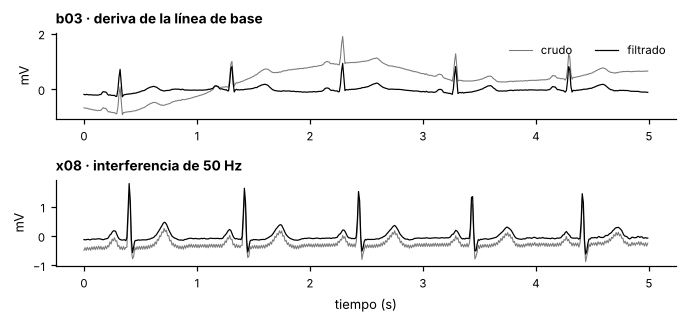

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(ANCHO, 3.0))
for ax, (rec, t0, titulo) in zip(axs, [("b03", 3 * 3600 + 600, "b03 · deriva de la línea de base"),
                                       ("x08", 2 * 3600, "x08 · interferencia de 50 Hz")]):
    ecg, fs = load_ecg(rec)
    i = slice(int(t0 * fs), int((t0 + 5) * fs))
    t = np.arange(i.stop - i.start) / fs
    ax.plot(t, ecg[i], color=GRIS, lw=0.7, label="crudo")
    ax.plot(t, apply_zero_phase(ecg, sos)[i], color="black", lw=0.8, label="filtrado")
    ax.set(title=titulo, ylabel="mV")
axs[0].legend(loc="upper right", ncol=2)
axs[1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "02_filtro_tiempo")

La deriva desaparece y la señal queda centrada en cero; la alternancia de 50 Hz se elimina. Los picos R quedan en el mismo lugar (fase cero) y con la misma forma.

## 2. Los latidos

Hay dos fuentes posibles para ubicar cada latido:

- **Las marcas de la base** (archivos `.qrs`). Las generó un detector automático y **no están revisadas** por un experto. No marcan el pico R sino un punto del QRS, así que el pico se busca a ±30 ms de cada marca con la polaridad del registro.
- **Un detector propio**: el algoritmo de Pan y Tompkins (1985) adaptado a 100 Hz. Sus etapas, sobre 6 s de `a03`:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_pan_tompkins.png')

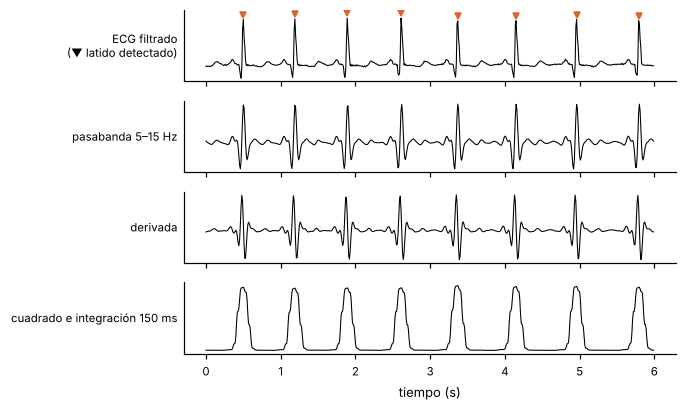

In [5]:
ecg, fs = load_ecg("a03")
x = apply_zero_phase(ecg, sos)
bp, d, mwi = pan_tompkins_signals(x, fs)
k = detect_r_peaks(x, fs)
i = slice(int(3600 * fs), int(3606 * fs))
t = np.arange(i.stop - i.start) / fs
fig, axs = plt.subplots(4, 1, figsize=(ANCHO, 3.8), sharex=True)
etapas = [(x, ""), (bp, "pasabanda 5–15 Hz"), (d, "derivada"), (mwi, "cuadrado e integración 150 ms")]
for ax, (s, nombre) in zip(axs, etapas):
    ax.plot(t, s[i], color="black", lw=0.7)
    if nombre:
        ax.set_ylabel(nombre, rotation=0, ha="right", va="center", fontsize=7.5)
    ax.set_yticks([])
kk = k[(k >= i.start) & (k < i.stop)]
axs[0].plot((kk - i.start) / fs, x[kk] + 0.3, "v", color=APNEA, ms=4)
axs[0].set_ylabel("ECG filtrado\n(▼ latido detectado)", rotation=0, ha="right", va="center", fontsize=7.5)
axs[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "02_pan_tompkins")

**Cómo funciona.** El pasabanda de 5–15 Hz se queda con la banda donde el QRS tiene más energía y saca las ondas P y T, más lentas. La derivada resalta las pendientes empinadas del QRS. El cuadrado la hace positiva (así el detector no depende de la polaridad del R) y realza las pendientes grandes sobre las chicas. La integración en 150 ms (el ancho típico de un QRS) junta toda la energía de cada complejo en un solo pulso. Sobre ese pulso, un **umbral adaptativo** que sigue los niveles de señal y de ruido decide si hay un latido; además hay un período refractario de 200 ms, un descarte de ondas T (picos a menos de 360 ms del anterior con menos de la mitad de su pendiente) y una búsqueda hacia atrás cuando pasa demasiado tiempo sin latidos. Las etapas lineales están centradas, así que no introducen retardo.

### ¿Coinciden las dos fuentes?

Se corren las dos en los 67 registros. Para cada latido del detector propio se busca la marca de la base más cercana.

latidos del detector propio a ≤30 ms de una marca: 96.4 %; a ≤150 ms: 96.9 %


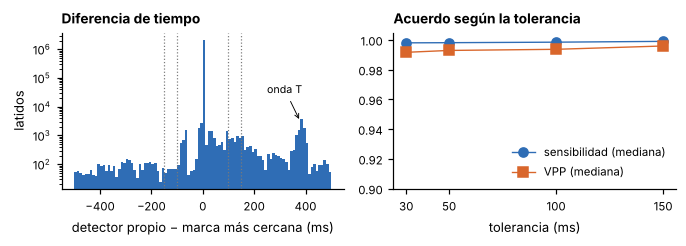

In [6]:
def comparar(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    qrs = load_qrs(rec)
    off, sign = qrs_reference(x, qrs, fs)
    tb = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
    tp = detect_r_peaks(x, fs) / fs
    j = np.clip(np.searchsorted(tb, tp), 1, len(tb) - 1)
    dif = np.where(np.abs(tp - tb[j - 1]) < np.abs(tp - tb[j]), tp - tb[j - 1], tp - tb[j])
    fila = {"record": rec, "latidos_base": len(tb), "latidos_propio": len(tp),
            "corr_base": 100 * clean_rr(tb)[2].mean(), "corr_propio": 100 * clean_rr(tp)[2].mean()}
    for tol in (0.03, 0.05, 0.10, 0.15):
        v = validate_against_reference(np.rint(tp * fs), np.rint(tb * fs), fs, tol)
        fila[f"Se_{int(1000 * tol)}"], fila[f"VPP_{int(1000 * tol)}"] = v["Se"], v["VPP"]
    return fila, dif

with ProcessPoolExecutor(4) as ex:
    res = list(ex.map(comparar, split.record))
comp = pd.DataFrame([r for r, _ in res]).merge(split[["record", "set", "category"]])
difs = np.concatenate([d for _, d in res])

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.3))
ax[0].hist(1000 * difs[np.abs(difs) < 0.5], bins=np.arange(-500, 505, 10), color=NORMAL)
ax[0].set(yscale="log", xlabel="detector propio − marca más cercana (ms)", ylabel="latidos",
          title="Diferencia de tiempo")
for tol in (100, 150):
    ax[0].axvline(-tol, color=GRIS, ls=":", lw=0.8); ax[0].axvline(tol, color=GRIS, ls=":", lw=0.8)
ax[0].annotate("onda T", xy=(380, 3000), xytext=(250, 3e4), fontsize=7, arrowprops=dict(arrowstyle="->", lw=0.6))
tols = [30, 50, 100, 150]
ax[1].plot(tols, [comp[f"Se_{t}"].median() for t in tols], "o-", color=NORMAL, label="sensibilidad (mediana)")
ax[1].plot(tols, [comp[f"VPP_{t}"].median() for t in tols], "s-", color=APNEA, label="VPP (mediana)")
ax[1].set(xlabel="tolerancia (ms)", ylabel="", ylim=(0.9, 1.005), title="Acuerdo según la tolerancia",
          xticks=tols)
ax[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "02_acuerdo_detectores")
print(f"latidos del detector propio a ≤30 ms de una marca: {100 * np.mean(np.abs(difs) <= 0.03):.1f} %; "
      f"a ≤150 ms: {100 * np.mean(np.abs(difs) <= 0.15):.1f} %")

**Qué se ve.** Cuando las dos fuentes encuentran el mismo latido, lo ubican a menos de 30 ms una de otra (el 96,4 % de las detecciones; el eje vertical es logarítmico). Entre 30 y 150 ms cae solo un 0,5 % más; el resto está lejos, como el grupo a +380 ms, que son ondas T marcadas por el detector propio. Es decir, las diferencias son latidos que una fuente encontró y la otra no, no latidos ubicados distinto. Por eso **la tolerancia casi no cambia el resultado**: la sensibilidad y el valor predictivo positivo (VPP) varían menos de un punto entre 30 y 150 ms. Para comparar dos detectores, la sensibilidad es la fracción de marcas de la base que el detector propio también encuentra y el VPP, la fracción de detecciones propias que tienen una marca de la base cerca. Se usa 100 ms, por debajo de los 150 ms de la norma de evaluación de detectores (ANSI/AAMI EC57).

Las diferencias, entonces, son **latidos perdidos o de más**. ¿Quién se equivoca? Se revisaron a mano 50 discrepancias elegidas al azar (`docs/revision_qrs_50.csv`):

In [7]:
rev = pd.read_csv(ROOT / "docs" / "revision_qrs_50.csv")
rev["tipo"] = rev.tipo.map({"FP": "solo lo marca el detector propio", "FN": "solo lo marca la base"})
pd.crosstab(rev.clasificacion, rev.tipo, margins=True, margins_name="total")

tipo,solo lo marca el detector propio,solo lo marca la base,total
clasificacion,,,
dudoso,8,3,11
error de las marcas de la base,18,0,18
error del detector,20,1,21
total,46,4,50


Hay errores de los dos lados. La base se saltea QRS visibles; el detector propio marca a veces el final de la onda T o ráfagas de ruido. Los tres patrones más claros:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_casos_detectores.png')

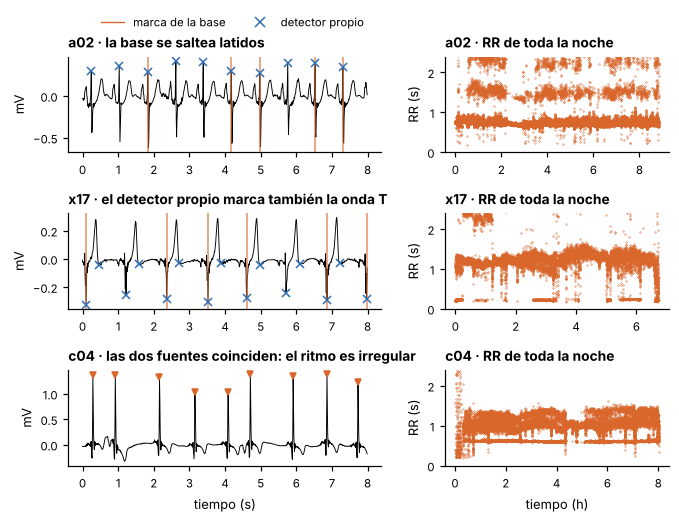

In [8]:
def tramo(rec, t0, dur=8):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, sos)
    qrs = load_qrs(rec)
    off, sign = qrs_reference(x, qrs, fs)
    tb = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
    tp = detect_r_peaks(x, fs) / fs
    return x, fs, tb, tp

casos = [("a02", 7535, "a02 · la base se saltea latidos"),
         ("x17", 4157, "x17 · el detector propio marca también la onda T")]
fig, axs = plt.subplots(3, 2, figsize=(ANCHO, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
for row, (rec, t0, titulo) in enumerate(casos):
    x, fs, tb, tp = tramo(rec, t0)
    i = slice(int(t0 * fs), int((t0 + 8) * fs))
    t = np.arange(i.start, i.stop) / fs
    axs[row, 0].plot(t - t0, x[i], color="black", lw=0.6)
    for tt in tb[(tb >= t0) & (tb < t0 + 8)]:
        axs[row, 0].axvline(tt - t0, color=APNEA, lw=1.2, alpha=0.6)
    sel = tp[(tp >= t0) & (tp < t0 + 8)]
    axs[row, 0].plot(sel - t0, x[np.rint(sel * fs).astype(int)], "x", color=NORMAL, ms=5)
    axs[row, 0].set(title=titulo, ylabel="mV")
    rr = np.diff(tb)
    axs[row, 1].plot(tb[1:] / 3600, rr, ".", ms=0.6, color=APNEA, label="con la base")
    axs[row, 1].set(ylim=(0, 2.4), ylabel="RR (s)", title=f"{rec} · RR de toda la noche")
axs[0, 0].plot([], [], color=APNEA, label="marca de la base"); axs[0, 0].plot([], [], "x", color=NORMAL, label="detector propio")
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.35, 1.03))
x, fs, tb, tp = tramo("c04", 9367)
i = slice(int(9367 * fs), int(9375 * fs)); t = np.arange(i.start, i.stop) / fs
axs[2, 0].plot(t - 9367, x[i], color="black", lw=0.6)
sel = tb[(tb >= 9367) & (tb < 9375)]
axs[2, 0].plot(sel - 9367, x[np.rint(sel * fs).astype(int)], "v", color=APNEA, ms=4)
axs[2, 0].set(title="c04 · las dos fuentes coinciden: el ritmo es irregular", ylabel="mV", xlabel="tiempo (s)")
axs[2, 1].plot(tb[1:] / 3600, np.diff(tb), ".", ms=0.6, color=APNEA)
axs[2, 1].set(ylim=(0, 2.4), ylabel="RR (s)", xlabel="tiempo (h)", title="c04 · RR de toda la noche")
fig.tight_layout()
save(fig, "02_casos_detectores")

**Qué se ve.**
- **a02**: el QRS tiene una onda R chica y una S profunda, y la base se saltea latidos enteros. En el RR de toda la noche aparece una segunda banda al doble del RR normal (~1,5 s): son los latidos perdidos. El detector propio los encuentra.
- **x17**: el QRS es chico e invertido y la onda T es grande. El detector propio marca además un punto al final de la T. En el RR aparecen bandas cortas (~0,25 s) y largas.
- **c04**: las dos fuentes encuentran los mismos latidos, pero el RR salta entre varios niveles durante toda la noche (0,6, 1,0 y 1,3 s). No es un error de detección: es un **ritmo irregular** (latidos prematuros frecuentes). En esos tramos el RR no refleja la regulación autonómica que interesa, y la limpieza del RR (sección 4) los deja afuera.

### Una regla para elegir la fuente sin usar etiquetas

Los dos tipos de error dejan intervalos **imposibles**: un latido perdido deja un RR del doble y uno de más, dos RR cortos. La limpieza del RR (sección 4) los detecta y los corrige. Entonces **la fracción de RR corregidos mide los errores de detección de cada fuente sin mirar las etiquetas de apnea**. La figura compara las dos fuentes en cada registro:

fuente
base      [a01, a09, a14, a18, b04, c01, c02, c03, c04, ...
propio    [a02, a03, a04, a05, a06, a07, a08, a10, a11, ...
Name: record, dtype: object

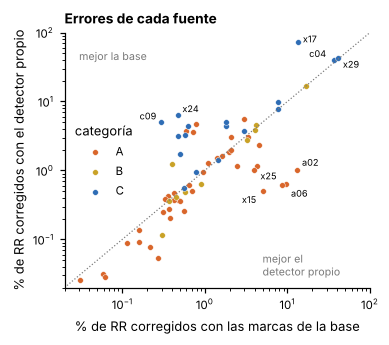

In [9]:
fig, ax = plt.subplots(figsize=(3.6, 3.2))
for cat, g in comp.groupby("category"):
    ax.scatter(g.corr_base, g.corr_propio, s=14, color=COLORES_CAT[cat], label=cat, edgecolor="white", lw=0.3)
lim = (0.02, 100)
ax.plot(lim, lim, color=GRIS, lw=0.8, ls=":")
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="% de RR corregidos con las marcas de la base",
       ylabel="% de RR corregidos con el detector propio", title="Errores de cada fuente")
desplaz = {"a02": (3, 3), "a06": (3, -8), "x25": (-14, 4), "x15": (-14, -8), "x17": (3, 0), "c04": (-16, 2),
           "x29": (3, -6), "c09": (-14, 2), "x24": (3, 2)}
for rec_, (dx, dy) in desplaz.items():
    rr_ = comp.set_index("record").loc[rec_]
    ax.annotate(rec_, (rr_.corr_base, rr_.corr_propio), fontsize=6, xytext=(dx, dy), textcoords="offset points")
ax.text(0.03, 40, "mejor la base", fontsize=7, color=GRIS)
ax.text(5, 0.03, "mejor el\ndetector propio", fontsize=7, color=GRIS)
ax.legend(loc="center left", title="categoría")
fig.tight_layout()
save(fig, "02_regla_fuente")
comp["fuente"] = np.where(comp.corr_propio < comp.corr_base, "propio", "base")
comp["corr_elegida"] = comp[["corr_base", "corr_propio"]].min(axis=1)
comp.groupby("fuente").record.apply(list)

**Qué se ve.** La mayoría de los registros está cerca de la diagonal: las dos fuentes andan igual. Los controles (C, azul) tienden a quedar arriba: son registros de amplitud baja y con más ruido de alta frecuencia (`01`), donde el detector propio confunde más la onda T con un QRS. Pero hay registros donde la base pierde muchos latidos (`a02`, `a06`, `x15`, `x25`, con 5–13 % de RR corregidos que bajan a menos de 1 % con el detector propio) y otros donde el detector propio marca ondas T (`x17`, `c09`, `x24`). En `c04` y `x29` las dos fuentes dan ~40 %: el ritmo es irregular.

**Regla adoptada:** en cada registro se usan los latidos de la fuente con **menos RR corregidos** (`src/qrs/beats.py`, `source="auto"`). No usa etiquetas, así que puede aplicarse igual en test. El efecto sobre los minutos que quedan para analizar (los que tienen 20 % o menos de RR corregidos, sección 4):

In [10]:
def minutos_validos(rec):
    out = {}
    for fuente in ("marks", "pt"):
        b = record_beats(rec, fuente)
        t, _, corr = clean_rr(b["t_r"])
        n = int(np.ceil(t[-1] / 60))
        q = minute_quality(t, corr, n)
        out[fuente] = int(np.sum(q <= 0.2))
    return rec, out

with ProcessPoolExecutor(4) as ex:
    mv = dict(ex.map(minutos_validos, split.record))
comp["min_validos_base"] = comp.record.map(lambda r: mv[r]["marks"])
comp["min_validos_propio"] = comp.record.map(lambda r: mv[r]["pt"])
comp["min_validos_elegida"] = np.where(comp.fuente == "propio", comp.min_validos_propio, comp.min_validos_base)
efecto = comp[comp.fuente == "propio"][["record", "corr_base", "corr_propio", "min_validos_base", "min_validos_elegida"]]
print("minutos con ≤ 20 % de RR corregidos — solo base:", comp.min_validos_base.sum(),
      "· con la regla:", comp.min_validos_elegida.sum())
efecto.sort_values("corr_base", ascending=False).round(1).head(15)

minutos con ≤ 20 % de RR corregidos — solo base: 31134 · con la regla: 31732


,record,corr_base,corr_propio,min_validos_base,min_validos_elegida
24,b05,16.8,16.7,358,379
1,a02,13.2,1.0,314,528
5,a06,9.7,0.6,373,510
57,x25,8.5,0.6,464,509
48,x15,5.1,0.5,471,518
11,a12,4.6,2.3,533,563
46,x13,4.3,1.2,477,509
44,x11,4.1,3.8,455,456
47,x14,4.0,1.0,447,488
52,x19,3.3,3.1,490,489


## 3. Refinamiento del pico R

A 100 Hz hay una muestra cada 10 ms, así que el pico R detectado puede estar hasta 5 ms antes o después del verdadero, y cada RR arrastra un error de hasta ±10 ms. Para ubicar el pico entre muestras se ajusta una **parábola** por la muestra máxima y sus dos vecinas y se toma su vértice (interpolación parabólica de 3 puntos).

,sin refinar,refinado
median,10.00,2.55
mean,10.01,2.34


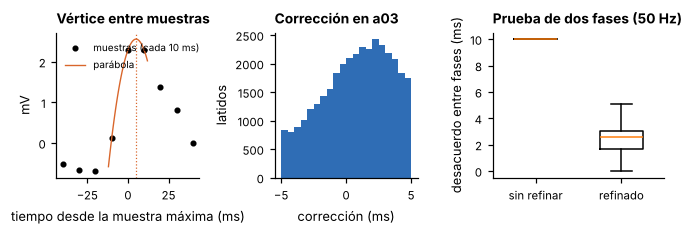

In [11]:
ecg, fs = load_ecg("a03")
x = apply_zero_phase(ecg, sos)
qrs = load_qrs("a03")
off, sign = qrs_reference(x, qrs, fs)
k = np.rint(r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0] * fs).astype(int)
kr, _ = refine_peaks_parabolic(sign * x, k)
j = int(np.argmax(np.abs(kr - k)[1000:2000])) + 1000      # un latido con corrección grande
c = k[j]
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
tt = np.arange(c - 4, c + 5)
ax[0].plot((tt - c) * 10, x[tt], "o", color="black", ms=3, label="muestras (cada 10 ms)")
y0, y1, y2 = x[c - 1], x[c], x[c + 1]
a_, b_ = (y0 - 2 * y1 + y2) / 2, (y2 - y0) / 2
u = np.linspace(-1.2, 1.2, 100)
ax[0].plot(u * 10, a_ * u ** 2 + b_ * u + y1, color=APNEA, label="parábola")
ax[0].axvline((kr[j] - c) * 10, color=APNEA, ls=":", lw=0.8)
ax[0].set(xlabel="tiempo desde la muestra máxima (ms)", ylabel="mV", title="Vértice entre muestras")
ax[0].legend(loc="upper left", fontsize=6.5)
ax[1].hist(10 * (kr - k), bins=np.arange(-5, 5.5, 0.5), color=NORMAL)
ax[1].set(xlabel="corrección (ms)", ylabel="latidos", title="Corrección en a03")

fases = []
for rec in DEV[:12]:
    ecg_, fs_ = load_ecg(rec)
    x_ = apply_zero_phase(ecg_, sos)
    q_ = load_qrs(rec)
    o_, s_ = qrs_reference(x_, q_, fs_)
    tf = two_phase_peaks(x_, q_, fs_, o_, s_)
    fases.append(pd.DataFrame({"sin refinar": 1000 * np.abs(tf.par - tf.impar),
                               "refinado": 1000 * np.abs(tf.par_ref - tf.impar_ref)}))
fases = pd.concat(fases)
ax[2].boxplot([fases["sin refinar"], fases["refinado"]], showfliers=False, widths=0.5)
ax[2].set_xticks([1, 2]); ax[2].set_xticklabels(["sin refinar", "refinado"])
ax[2].set(ylabel="desacuerdo entre fases (ms)", title="Prueba de dos fases (50 Hz)")
fig.tight_layout()
save(fig, "02_refinamiento")
fases.agg(["median", "mean"]).round(2)

**Cómo se verifica sin una referencia de mayor resolución.** Se arma una prueba de dos fases: el ECG se baja a 50 Hz tomando las muestras pares por un lado y las impares por otro. Cada latido queda medido en dos grillas corridas 10 ms. Si los dos tiempos coinciden después de refinar, el refinamiento recupera la posición entre muestras. El desacuerdo medio baja de ~10 ms a unos pocos ms.

**¿Importa para la hipótesis?** El error de cuantización es como un ruido blanco agregado al RR: se reparte en todas las frecuencias. En la banda lenta de la feature (0,01–0,05 Hz), donde está la oscilación de la apnea, su potencia es despreciable frente a la del RR:

In [12]:
t_ent = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
t_ref = r_peaks_from_marks(x, qrs, fs, off, sign, refine=True)[0]
n = min(len(t_ent), len(t_ref))
tr, rr_ref, _ = clean_rr(t_ref)
_, rr_ent, _ = clean_rr(t_ent)
m = min(len(rr_ref), len(rr_ent))
err = (rr_ent[:m] - rr_ref[:m])
grid = np.arange(tr[0], tr[m - 1], 0.5)
fr, p_rr = welch(np.interp(grid, tr[:m], rr_ref[:m]), fs=2, nperseg=240)
_, p_err = welch(np.interp(grid, tr[:m], err), fs=2, nperseg=240)
banda = (fr >= 0.01) & (fr <= 0.05)
print(f"a03 · potencia del error de cuantización / potencia del RR en 0,01–0,05 Hz: "
      f"{100 * p_err[banda].sum() / p_rr[banda].sum():.3f} %; en 0,15–0,4 Hz: "
      f"{100 * p_err[(fr >= 0.15) & (fr <= 0.4)].sum() / p_rr[(fr >= 0.15) & (fr <= 0.4)].sum():.1f} %")

a03 · potencia del error de cuantización / potencia del RR en 0,01–0,05 Hz: 0.033 %; en 0,15–0,4 Hz: 1.7 %


Para la feature de este trabajo el refinamiento casi no cambia nada; sí pesa en la banda respiratoria y en índices latido a latido como el RMSSD. Se mantiene porque no cuesta nada y deja una serie RR correcta para cualquier otro uso.

## 4. Limpieza de la serie RR

Aun con la mejor fuente quedan intervalos que no son un latido normal tras otro: latidos perdidos o de más, y **latidos ectópicos** (un latido prematuro que deja un RR corto seguido de uno largo). Las reglas (`src/qrs/rr_clean.py`):

1. Un RR fuera de **0,3–2 s** (200 a 30 latidos por minuto) es imposible en reposo: se corrige.
2. Un RR que se aparta más de un **20 %** de la mediana de sus 11 vecinos se corrige (ectópico o error de detección).
3. Los RR corregidos se reemplazan por **interpolación lineal** entre los válidos vecinos.
4. Un minuto con más de **20 %** de RR corregidos se excluye: ahí la serie es más interpolación que dato.

¿Por qué 20 %? La figura muestra cuánto se aparta cada RR de la mediana de sus vecinos, en todos los latidos de desarrollo con la fuente elegida.

RR a menos de 10 % de la mediana: 96.8 % · a más de 20 %: 1.13 %


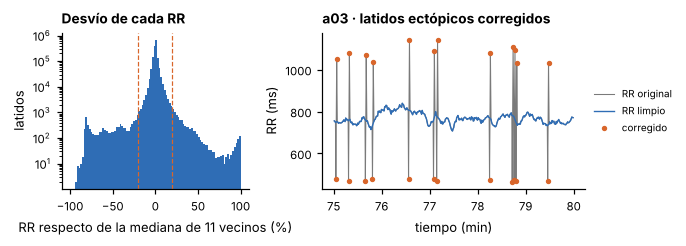

In [13]:
def desvios(args):
    rec, fuente = args
    t = record_beats(rec, fuente)["t_r"]
    rr = np.diff(t)
    med = pd.Series(np.where((rr < 0.3) | (rr > 2), np.nan, rr)).rolling(11, center=True, min_periods=1).median()
    return (rr / med.to_numpy() - 1)

with ProcessPoolExecutor(4) as ex:
    fuentes = comp.set_index("record").fuente.map({"base": "marks", "propio": "pt"})
    dv = np.concatenate(list(ex.map(desvios, [(r, fuentes[r]) for r in DEV])))
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].hist(100 * dv[np.isfinite(dv)], bins=np.arange(-100, 101, 2), color=NORMAL)
for v in (-20, 20):
    ax[0].axvline(v, color=APNEA, ls="--", lw=0.8)
ax[0].set(yscale="log", xlabel="RR respecto de la mediana de 11 vecinos (%)", ylabel="latidos",
          title="Desvío de cada RR")
b = record_beats("a03", "marks")
t, rr_c, corr = clean_rr(b["t_r"])
rr_raw = np.diff(b["t_r"])
sel = (t >= 75 * 60) & (t < 80 * 60)
ax[1].plot(t[sel] / 60, 1000 * rr_raw[sel], color=GRIS, lw=0.7, label="RR original")
ax[1].plot(t[sel] / 60, 1000 * rr_c[sel], color=NORMAL, lw=0.9, label="RR limpio")
ax[1].plot(t[sel & corr] / 60, 1000 * rr_raw[sel & corr], "o", color=APNEA, ms=2.5, label="corregido")
ax[1].set(xlabel="tiempo (min)", ylabel="RR (ms)", title="a03 · latidos ectópicos corregidos")
ax[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=6.5)
fig.tight_layout()
save(fig, "02_limpieza_rr")
dvf = dv[np.isfinite(dv)]
print(f"RR a menos de 10 % de la mediana: {100 * np.mean(np.abs(dvf) < 0.1):.1f} % · "
      f"a más de 20 %: {100 * np.mean(np.abs(dvf) > 0.2):.2f} %")

**Qué se ve.** Casi todos los RR están a menos de 10 % de la mediana de sus vecinos (el número exacto se imprime arriba): la frecuencia cardíaca cambia de a poco de un latido a otro. Más allá de ±20 % la distribución es casi plana y tiene picos propios, que son errores: +100 % es un latido perdido (el RR se duplica), −50 % un latido de más en el medio y −80 % una onda T marcada como latido. Solo ~1 % de los RR queda fuera de ±20 %. El umbral de 20 % queda entre el cuerpo de la distribución y esas colas. A la derecha, los ectópicos de `a03` reemplazados por interpolación: el RR limpio conserva la variación lenta y la respiratoria.

## 5. Resumen

| Paso | Decisión | Por qué |
|---|---|---|
| Filtro | Butterworth 0,5–45 Hz, orden 3, ida y vuelta | Saca la deriva y el ruido > 45 Hz (con un cero en 50 Hz); es el menor orden que respeta el latido |
| Fuente de latidos | En cada registro, la que deja menos RR corregidos (marcas de la base o detector propio) | Las marcas pierden latidos en algunos registros y el detector propio marca ondas T en otros; la regla no usa etiquetas |
| Tolerancia de comparación | 100 ms | Cuando las fuentes coinciden lo hacen a < 30 ms; la tolerancia no cambia el resultado |
| Refinamiento | Parábola de 3 puntos | Baja el error de cuantización de ~10 a pocos ms; en la banda de la feature su efecto es despreciable |
| Limpieza del RR | 0,3–2 s y ±20 % de la mediana de 11 vecinos; interpolación lineal; se excluyen los minutos con > 20 % corregido | El 20 % separa la variación normal de los ectópicos y errores |

Lo nuevo respecto de la primera versión es la **elección de la fuente por registro**. Su efecto sobre la detección de apnea se mide en `04`.